In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("Libraries imported successfully!")


Libraries imported successfully!


In [28]:
titles = pd.read_csv("data/titles.csv")
credits = pd.read_csv("data/credits.csv")

In [29]:
# Step 1: Create a cleaned Titles dataset
#here we are cleaning the duplicate values by removing the repated once

titles_clean = titles.drop_duplicates(
    subset="id",
    keep="first"
).copy()


# Step 2: Create a cleaned Credits dataset

credits_clean = credits.drop_duplicates().copy()
#credits to clean the datasets


# Step 3: Check the results

print("Original Titles:", len(titles))
print("Cleaned Titles:", len(titles_clean))

print("Original Credits:", len(credits))
print("Cleaned Credits:", len(credits_clean))

Original Titles: 9871
Cleaned Titles: 9868
Original Credits: 124235
Cleaned Credits: 124179


In [30]:
#merge titles and credits datasets
merged_data = pd.merge(titles_clean,credits_clean, on ="id",how ="left")
#here on id tells that we are merging the datasets which have the same id and 
# how left tells that we are keeping all the values keep even in the titles_clean having no matching credits in second datasets 
#display the results
print("Merged Datasets Shapes:",merged_data.shape)
display(merged_data.head())

Merged Datasets Shapes: (125186, 19)


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,person_id,name,character,role
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,59401.0,Joe Besser,Joe,ACTOR
1,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,31460.0,Moe Howard,Moe,ACTOR
2,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,31461.0,Larry Fine,Larry,ACTOR
3,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0,21174.0,Buster Keaton,Johnny Gray,ACTOR
4,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0,28713.0,Marion Mack,Annabelle Lee,ACTOR


In [31]:
# Check duplicate records

print("Duplicate rows in Titles:",
      titles.duplicated().sum())

print("Duplicate IDs in Titles:",
      titles["id"].duplicated().sum())

print("Duplicate rows in Credits:",
      credits.duplicated().sum())

Duplicate rows in Titles: 3
Duplicate IDs in Titles: 3
Duplicate rows in Credits: 56


In [32]:
# Missing values in both datasets

print("TITLES MISSING VALUES")
print(titles.isnull().sum())

print("\nCREDITS MISSING VALUES")
print(credits.isnull().sum())

TITLES MISSING VALUES
id                         0
title                      0
type                       0
description              119
release_year               0
age_certification       6487
runtime                    0
genres                     0
production_countries       0
seasons                 8514
imdb_id                  667
imdb_score              1021
imdb_votes              1031
tmdb_popularity          547
tmdb_score              2082
dtype: int64

CREDITS MISSING VALUES
person_id        0
id               0
name             0
character    16287
role             0
dtype: int64


In [33]:
# Explore datasets

print("Titles information:")
titles.info()

print("\nCredits information:")
credits.info()

print("\nMissing values in Titles:")
print(titles.isnull().sum())

print("\nMissing values in Credits:")
print(credits.isnull().sum())

Titles information:
<class 'pandas.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   str    
 1   title                 9871 non-null   str    
 2   type                  9871 non-null   str    
 3   description           9752 non-null   str    
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   str    
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   str    
 8   production_countries  9871 non-null   str    
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   str    
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5

In [34]:
titles = pd.read_csv("data/titles.csv")
credits = pd.read_csv("data/credits.csv")
print("titles:", titles.shape)
print("credits:",credits.shape)
print(titles.head())
print(credits.head())
      

titles: (9871, 15)
credits: (124235, 5)
        id                        title   type  \
0  ts20945            The Three Stooges   SHOW   
1  tm19248                  The General  MOVIE   
2  tm82253  The Best Years of Our Lives  MOVIE   
3  tm83884              His Girl Friday  MOVIE   
4  tm56584            In a Lonely Place  MOVIE   

                                         description  release_year  \
0  The Three Stooges were an American vaudeville ...          1934   
1  During America’s Civil War, Union spies steal ...          1926   
2  It's the hope that sustains the spirit of ever...          1946   
3  Hildy, the journalist former wife of newspaper...          1940   
4  An aspiring actress begins to suspect that her...          1950   

  age_certification  runtime  \
0             TV-PG       19   
1               NaN       78   
2               NaN      171   
3               NaN       92   
4               NaN       94   

                                             

In [35]:
#analysis1: Movies vs tv shows
content_count = titles_clean['type'].value_counts()
print("content Distibution:")
print(content_count)


content Distibution:
type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64


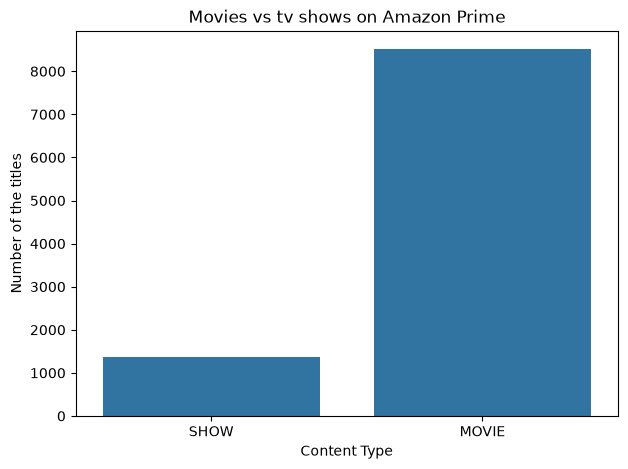

In [36]:
#visulalize Movies vs tv shows
plt.figure(figsize=(7,5))
sns.countplot(data=titles_clean,x="type")
plt.title("Movies vs tv shows on Amazon Prime")
plt.xlabel("Content Type")
plt.ylabel("Number of the titles")
plt.show()

In [37]:
#count titles by the release year
year_count = titles_clean["release_year"].value_counts().sort_index()
print(year_count)

release_year
1912      1
1914      2
1915      5
1916      2
1917      1
       ... 
2018    685
2019    807
2020    698
2021    856
2022     89
Name: count, Length: 110, dtype: int64


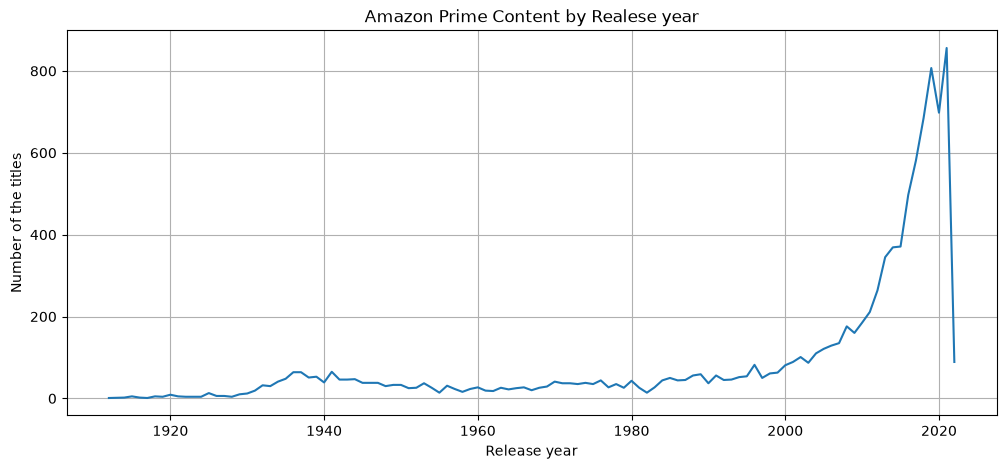

In [38]:
#to visulize the year wise result
plt.figure(figsize=(12,5))
#to create the graph we are here using plt.figure

plt.plot(year_count.index,year_count.values)
plt.title("Amazon Prime Content by Realese year")
plt.xlabel("Release year")
#means here x axis is year of realsing
plt.ylabel("Number of the titles")
plt.grid(True)
#adding the grids to it
plt.show()

In [39]:
#analysis 3: Explore genres
print(titles_clean["genres"].head(10))

0    ['comedy', 'family', 'animation', 'action', 'f...
1    ['action', 'drama', 'war', 'western', 'comedy'...
2                          ['romance', 'war', 'drama']
3                       ['comedy', 'drama', 'romance']
4                     ['thriller', 'drama', 'romance']
5                                 ['western', 'drama']
6    ['drama', 'family', 'fantasy', 'romance', 'com...
7                       ['thriller', 'drama', 'crime']
8                       ['comedy', 'romance', 'drama']
9                                   ['crime', 'drama']
Name: genres, dtype: str


In [40]:
genres = titles_clean.explode("genres")
print(genres["genres"].head(15))

0     ['comedy', 'family', 'animation', 'action', 'f...
1     ['action', 'drama', 'war', 'western', 'comedy'...
2                           ['romance', 'war', 'drama']
3                        ['comedy', 'drama', 'romance']
4                      ['thriller', 'drama', 'romance']
5                                  ['western', 'drama']
6     ['drama', 'family', 'fantasy', 'romance', 'com...
7                        ['thriller', 'drama', 'crime']
8                        ['comedy', 'romance', 'drama']
9                                    ['crime', 'drama']
10                                 ['history', 'drama']
11                       ['thriller', 'crime', 'drama']
12                                           ['horror']
13                                   ['drama', 'crime']
14                     ['thriller', 'horror', 'action']
Name: genres, dtype: str


genres
['drama']                908
['comedy']               686
['documentation']        493
['horror']               217
[]                       209
['thriller']             189
['drama', 'romance']     181
['comedy', 'drama']      153
['drama', 'comedy']      151
['thriller', 'drama']    120
Name: count, dtype: int64


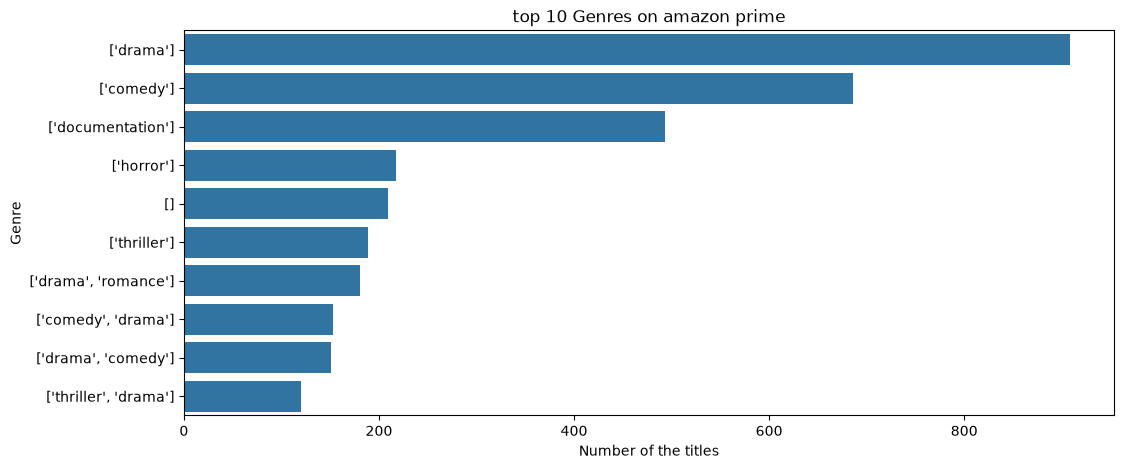

In [41]:
#step1 count the number of the titles in each category of the movies like romace,comedy thriller, drma these are also called as genre
genre_counts=genres["genres"].value_counts()
#step2 display the top 10 categories
print(genre_counts.head(10))
#step3 creating the graph

plt.figure(figsize=(12,5))
sns.barplot(x=genre_counts.head(10).values,y=genre_counts.head(10).index)
plt.title("top 10 Genres on amazon prime")
plt.xlabel("Number of the titles")
plt.ylabel("Genre")
plt.show()


In [42]:
genre_counts = (
    genres[genres["genres"] != ""]
    ["genres"]
    .value_counts()
)

print(genre_counts.head(10))


genres
['drama']                908
['comedy']               686
['documentation']        493
['horror']               217
[]                       209
['thriller']             189
['drama', 'romance']     181
['comedy', 'drama']      153
['drama', 'comedy']      151
['thriller', 'drama']    120
Name: count, dtype: int64


In [43]:
import ast
#here ast means abstact syntax trees used to safly converts python representation strings containg the list
genres_data = titles_clean.copy()
#here cleaning the data sets
genres_data["genres"] = genres_data["genres"].apply
(
    lambda x: ast.literal_eval(x)
    if isinstance(x,str) and x.startswith("[")
    else []
)
#separate individual genres into rows

genre_data = genres_data.explode("genres")
#count each genre
genre_counts = genre_data["genres"].value_counts()
#diaplaying top 10 categories of the movies
print(genre_counts.head(10))


genres
<bound method Series.apply of 0       ['comedy', 'family', 'animation', 'action', 'f...\n1       ['action', 'drama', 'war', 'western', 'comedy'...\n2                             ['romance', 'war', 'drama']\n3                          ['comedy', 'drama', 'romance']\n4                        ['thriller', 'drama', 'romance']\n                              ...                        \n9866                                            ['drama']\n9867                                           ['comedy']\n9868                                            ['crime']\n9869                                  ['family', 'drama']\n9870                                            ['drama']\nName: genres, Length: 9868, dtype: str>    9868
Name: count, dtype: int64


In [44]:
import pandas as pd
titles = pd.read_csv("data/titles.csv")
print(titles.shape)

(9871, 15)


In [45]:
import ast
#convert genre strings into actual python lists
titles_clean = titles.drop_duplicates()
genres_data = titles_clean.copy()
genres_data["genres"] = genres_data["genres"].apply(
   lambda x: ast.literal_eval(x)
   if isinstance(x,str) and x.startswith("[")
   else [] 
)
#here ast.literal_eval(x) is used to convert into the pytho list
#LIKE ["drama,"comedy"]
#explode separates that lists into individuals rows
genre_data = genres_data.explode("genres")
#count each individual genre
genre_counts = genre_data["genres"].value_counts()
print(genre_counts.head(10))


genres
drama            4762
comedy           2987
thriller         2119
action           1820
romance          1751
crime            1250
documentation    1096
horror           1065
family            751
european          712
Name: count, dtype: int64


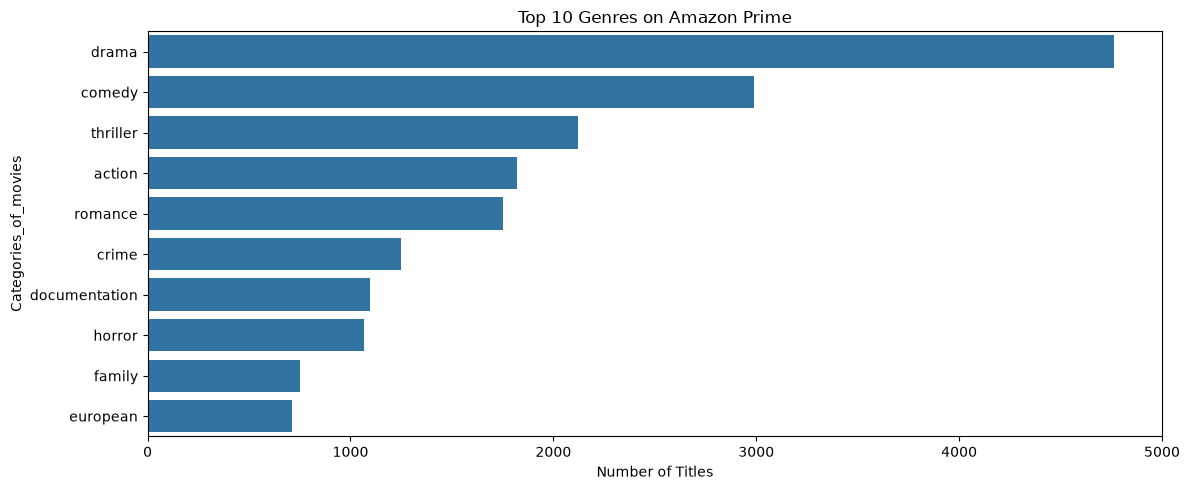

In [46]:
plt.figure(figsize=(12,5))
sns.barplot(x=genre_counts.head(10).values,y=genre_counts.head(10).index)
#here index means  getting the types of the names catogerios of the movies and values means getting count of the categories
plt.title("Top 10 Genres on Amazon Prime")
plt.xlabel("Number of Titles")
plt.ylabel("Categories_of_movies")
#tightlayout means adjusting the spacing
plt.tight_layout()
plt.show()

In [47]:
#for diplaying all the columns
print(titles_clean.columns.tolist())

['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']


In [48]:
#country wise content analysis
titles_clean = titles.drop_duplicates()
country_counts =(
    titles_clean["production_countries"]
    .dropna()
    #here dropna() means rmove the missing values
    .str.split(",")
    #here it will split the strings into coma separted values
#separte the python list
    .explode()
    .str.strip()
    .value_counts()
    #here count the values of the country is contributing ti the amazon prime
)
#diplay the top 10 countries
print("top 10 countries producing the amazon prime content:")
print(country_counts.head(10))

    

top 10 countries producing the amazon prime content:
production_countries
['US']    4807
['IN']    1048
[]         821
['GB']     667
['CA']     321
'US']      288
['US'      192
['JP']     172
['AU']     143
['XX']     120
Name: count, dtype: int64


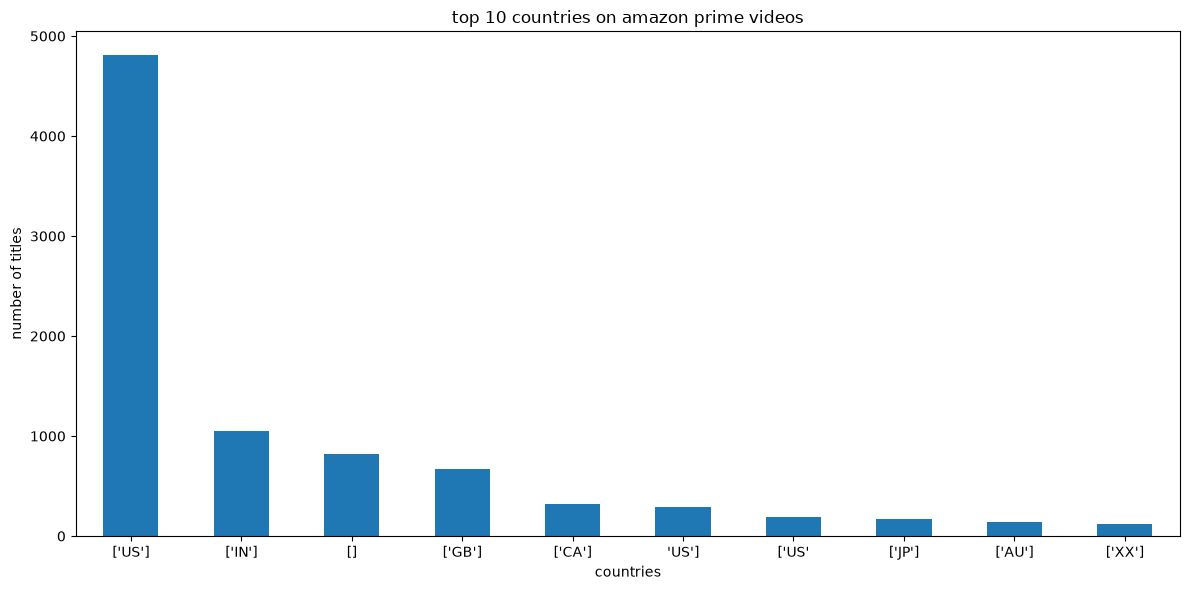

In [49]:
plt.figure(figsize=(12,6))
#here is used to plot the graph
country_counts.head(10).plot(kind="bar")
#gives the output of the top 10 counties
plt.title("top 10 countries on amazon prime videos")
#it is used to give the title for the graph
plt.xlabel("countries")
#x axis given name countires
plt.ylabel("number of titles")
#y axis given names titles 
plt.xticks(rotation=0)
#it helps to rotae the text in the graph means like long names united states of kingdom it will to in the slope inclined form
plt.tight_layout()
#it is ude to adjust the spacing of the graph
plt.show()
#display the graph

In [50]:

import ast
#here ast means bastarct syntax tree it used to safley covert into the python strings

# Convert country strings into actual Python lists
country_data = titles_clean["production_countries"].dropna().apply(
    ast.literal_eval
    #here it evaluate the list of the strings
    #means converting the string into real python list"["us","uk","india"]" this converted into ["us","uk","india"]
)

# Separate individual countries into rows
country_data = country_data.explode()

# Remove extra spaces and count countries
country_counts = country_data.str.strip().value_counts()

# Display top 10 countries
print(country_counts.head(10))


production_countries
US    5331
IN    1072
GB     928
CA     530
FR     250
JP     197
AU     173
DE     172
IT     143
CN     143
Name: count, dtype: int64


In [51]:
type_counts = titles_clean["type"].value_counts()
print(type_counts)

type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64


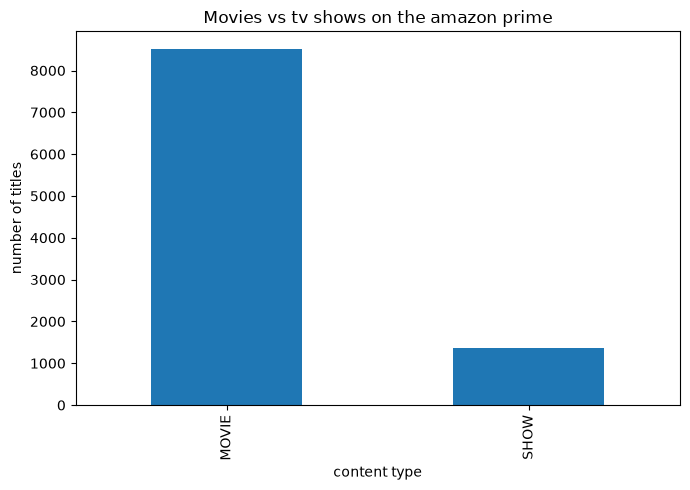

In [52]:
plt.figure(figsize=(7,5))
type_counts.plot(kind="bar")
plt.title("Movies vs tv shows on the amazon prime")
plt.xlabel("content type")
plt.ylabel("number of titles")
plt.tight_layout()
plt.show()

# Amazon Prime Video – Exploratory Data Analysis

## 1. Project Overview

This project aims to explore and analyze Amazon Prime Video content using Python.

The objective is to identify content distribution patterns, popular genres, country-wise production trends, and the differences between movies and TV shows.

## 2. Tools and Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Jupyter Notebook

## 3. Dataset

The project uses two datasets:
- titles.csv
- credits.csv

## 3. Dataset

This project uses two datasets:

- titles.csv – Contains information about movies and TV shows.
- credits.csv – Contains cast and crew information.

The datasets are used to analyze content distribution,
genres, production countries, and content types.

## 4. Exploratory Data Analysis (EDA)

The following analysis was performed:

1. Dataset overview and structure.
2. Identification of missing values.
3. Removal of duplicate records.
4. Analysis of popular movie genres.
5. Country-wise content distribution.
6. Comparison between movies and TV shows.

## 5. Key Findings and Observations

### 1. Content Type
- Movies: 8,511
- TV Shows: 1,357
- Movies dominate the Amazon Prime dataset.

### 2. Popular Genres
- Drama: 4,762
- Comedy: 2,987
- Thriller: 2,119
- Action: 1,820
- Romance: 1,751

Drama is the most frequently occurring genre.

### 3. Country-wise Production
- United States: 5,331
- India: 1,072
- United Kingdom: 928
- Canada: 530

The United States contributes the largest number of titles.

## 6. Conclusion

This Exploratory Data Analysis project helped identify
important patterns in Amazon Prime Video content.

Key conclusions:

- Movies are significantly more common than TV shows.
- Drama is the most popular genre in the dataset.
- The United States contributes the highest number of titles.
- The dataset provides useful insights into content distribution.

Through this project, I gained practical experience in
Python, Pandas, data cleaning, data analysis, and visualization.

## 7. Future Scope

- Perform more detailed analysis of release years.
- Analyze movie and TV show ratings.
- Explore relationships between cast, directors, and content.
- Build an interactive dashboard using Power BI or Streamlit.

In [53]:
import nbformat
from nbconvert import HTMLExporter

notebook = nbformat.read(
    "Amazon_Prime_EDA.ipynb",
    as_version=4
)

html_exporter = HTMLExporter()
html_exporter.exclude_input = True

body, resources = html_exporter.from_notebook_node(notebook)

with open("Amazon_Prime_EDA_Report.html", "w", encoding="utf-8") as f:
    f.write(body)

print("Output-only report created successfully!")

Output-only report created successfully!
